<a href="https://colab.research.google.com/github/ryanaxiom/Applied-ML/blob/main/code/Day24_Carnegie_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student Instructions**: Before you begin, click **File > Save a copy in Drive** so you do not lose your work!

In [1]:
url = ("https://raw.githubusercontent.com/ryanaxiom/Applied-ML/main/data/carnegie_data.csv")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
carnegie_raw = pd.read_csv(url, encoding="cp1252")
carnegie = carnegie_raw.copy()
carnegie["research"] = carnegie["serd"] + carnegie["nonserd"]
d = carnegie[carnegie["research"].notna()].copy()
d["med_yn"] = (d["medical"] == 1).astype(int)
y = d["research"]
kf = KFold(n_splits=5, shuffle=True, random_state=309)
five = ["fallenr20", "totdeg", "facnum", "stem_rsd", "med_yn"]
print(carnegie.shape, d.shape)

(3939, 102) (302, 103)


In [2]:
nh = pd.read_csv(url.replace("carnegie_data", "nhanes_adults"))
yd = (nh["Diabetes"] == "Yes").astype(int)
nh["male"] = (nh["Sex"] == "male").astype(int)
exam = ["Age", "BMI", "BPSysAve", "BPDiaAve", "Pulse",
        "TotChol", "DirectChol", "male"]
tr, te = next(iter(kf.split(nh)))                  # one fold
filled = nh[exam].fillna(nh[exam].iloc[tr].median())
from sklearn.ensemble import RandomForestClassifier
print(nh.shape, len(tr), len(te))

(11769, 22) 9415 2354


In [3]:
from sklearn.inspection import permutation_importance
noisy = filled.copy()
noisy["noise"] = np.random.default_rng(309).uniform(size=len(noisy))
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                            random_state=309)
rf.fit(noisy.iloc[tr], yd.iloc[tr])
built_in = pd.Series(rf.feature_importances_, index=noisy.columns)
print(built_in[["Age", "BMI", "noise", "male"]].round(3).to_dict())
shuffled = permutation_importance(rf, noisy.iloc[te], yd.iloc[te],
                                  scoring="roc_auc", n_repeats=5,
                                  random_state=309)
drop = pd.Series(shuffled.importances_mean, index=noisy.columns)
print(drop[["Age", "BMI", "noise", "male"]].round(3).to_dict())

{'Age': 0.31, 'BMI': 0.188, 'noise': 0.061, 'male': 0.009}
{'Age': 0.172, 'BMI': 0.028, 'noise': -0.001, 'male': 0.001}


In [4]:
print(built_in.sort_values(ascending=False).round(3).to_dict())
print(drop.sort_values(ascending=False).round(3).to_dict())

{'Age': 0.31, 'BMI': 0.188, 'TotChol': 0.156, 'BPSysAve': 0.083, 'BPDiaAve': 0.08, 'DirectChol': 0.067, 'noise': 0.061, 'Pulse': 0.047, 'male': 0.009}
{'Age': 0.172, 'TotChol': 0.037, 'BMI': 0.028, 'BPSysAve': 0.009, 'BPDiaAve': 0.007, 'Pulse': 0.004, 'DirectChol': 0.003, 'male': 0.001, 'noise': -0.001}


1 rounds: 2 distinct fitted values
10 rounds: 5 distinct fitted values
100 rounds: 17 distinct fitted values


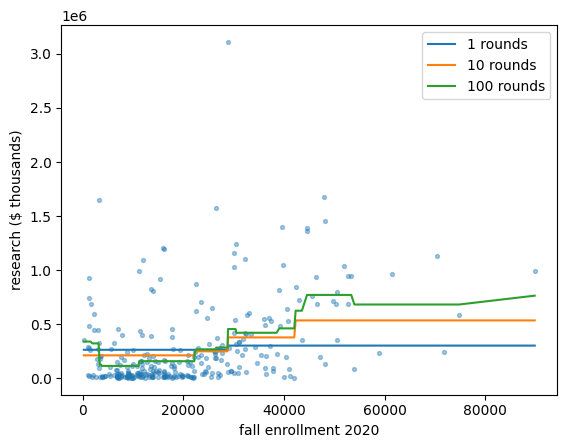

In [5]:
from sklearn.ensemble import GradientBoostingRegressor
x1 = d[["fallenr20"]]
stumps = GradientBoostingRegressor(max_depth=1, learning_rate=0.1, n_estimators=100,
                                   random_state=309)
stumps.fit(x1, y)
grid = x1.sort_values("fallenr20")                     # sort x first
plt.scatter(x1, y, s=8, alpha=0.4)
for k, pred in enumerate(stumps.staged_predict(grid), start=1):
    if k in [1, 10, 100]:
        plt.plot(grid, pred, label=f"{k} rounds")
        print(k, "rounds:", len(np.unique(pred.round(0))), "distinct fitted values")
plt.xlabel("fall enrollment 2020"); plt.ylabel("research ($ thousands)"); plt.legend(); plt.show()

In [11]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import log_loss
boost = GradientBoostingClassifier(max_depth=3, learning_rate=0.1,
                                   n_estimators=600,
                                   random_state=309)
boost.fit(filled.iloc[tr], yd.iloc[tr])
fit = [log_loss(yd.iloc[tr], p[:, 1])
       for p in boost.staged_predict_proba(filled.iloc[tr])]
held = [log_loss(yd.iloc[te], p[:, 1])
        for p in boost.staged_predict_proba(filled.iloc[te])]
for k in [1, 10, 50,59, 100, 600]:
    print(k, round(fit[k - 1], 4), round(held[k - 1], 4))
print(int(np.argmin(held)) + 1)

1 0.3963 0.3864
10 0.3434 0.3432
50 0.3094 0.3268
59 0.3063 0.3267
100 0.2982 0.3284
600 0.2332 0.3435
59


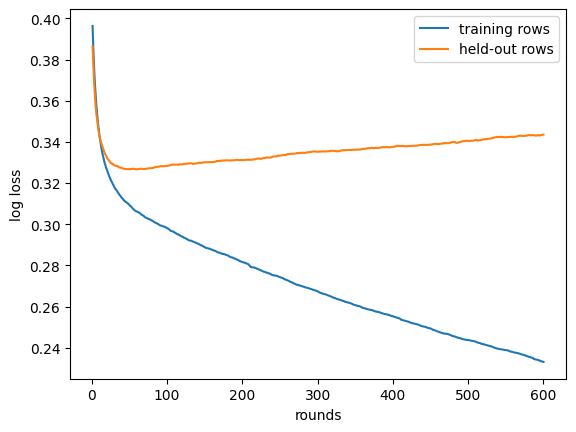

105 0.3261


In [7]:
plt.plot(range(1, 601), fit, label="training rows")
plt.plot(range(1, 601), held, label="held-out rows")
plt.xlabel("rounds"); plt.ylabel("log loss"); plt.legend(); plt.show()
slow = GradientBoostingClassifier(max_depth=3, learning_rate=0.05, n_estimators=600,
                                  random_state=309)
slow.fit(filled.iloc[tr], yd.iloc[tr])
held_slow = [log_loss(yd.iloc[te], p[:, 1])
             for p in slow.staged_predict_proba(filled.iloc[te])]
print(int(np.argmin(held_slow)) + 1, round(min(held_slow), 4))

In [12]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
for trees in [10, 200, 1000]:
    rf_b = RandomForestClassifier(n_estimators=trees, min_samples_leaf=20,
                                  random_state=309, n_jobs=-1)
    forest = make_pipeline(SimpleImputer(strategy="median"), rf_b)
    ll = cross_val_score(forest, nh[exam], yd, cv=kf, scoring="neg_log_loss")
    print(trees, round(-ll.mean(), 4))

10 0.3399
200 0.3283
1000 0.3283


In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier
boosting = HistGradientBoostingClassifier(learning_rate=0.05,
                                          random_state=309)
auc = cross_val_score(boosting, nh[exam], yd, cv=kf,
                      scoring="roc_auc")
ll = cross_val_score(boosting, nh[exam], yd, cv=kf,
                     scoring="neg_log_loss")
print(round(auc.mean(), 4), round(-ll.mean(), 4))

0.8057 0.3311


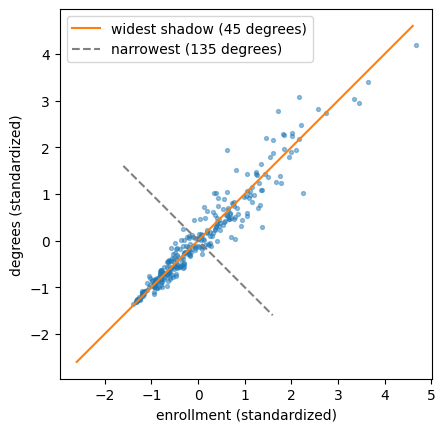

In [14]:
from sklearn.preprocessing import StandardScaler
pic_scaler = StandardScaler()
Zpic = pic_scaler.fit_transform(d[["fallenr20", "totdeg"]])
plt.scatter(Zpic[:, 0], Zpic[:, 1], s=8, alpha=0.45)
t = np.linspace(-2.6, 4.6, 2)
plt.plot(t, t, color="C1", label="widest shadow (45 degrees)")
s = np.linspace(-1.6, 1.6, 2)
plt.plot(s, -s, color="gray", linestyle="--", label="narrowest (135 degrees)")
plt.xlabel("enrollment (standardized)"); plt.ylabel("degrees (standardized)")
plt.gca().set_aspect("equal"); plt.legend(); plt.show()

In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()                       # mean 0, SD 1
Z = scaler.fit_transform(d[["fallenr20", "totdeg"]])
def width(angle):
    t = np.radians(angle)
    shadow = np.cos(t) * Z[:, 0] + np.sin(t) * Z[:, 1]
    return float(np.var(shadow))         # variance of the shadow
for angle in [0, 45, 90, 135]:
    print(angle, round(width(angle), 4))
widths = [width(a) for a in range(180)]         # every direction
print(int(np.argmax(widths)), round(max(widths), 4))
print(round(d["fallenr20"].corr(d["totdeg"]), 4))

0 1.0
45 1.9643
90 1.0
135 0.0357
45 1.9643
0.9643


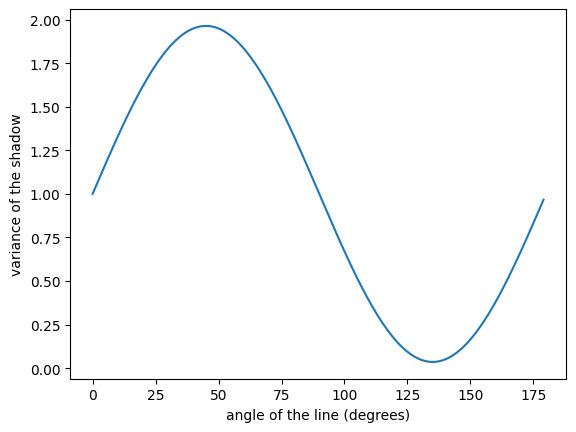

2.0


In [16]:
plt.plot(range(180), widths)
plt.xlabel("angle of the line (degrees)"); plt.ylabel("variance of the shadow"); plt.show()
print(round(width(45) + width(135), 4))

In [17]:
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(Z)                                      # the twins, again
print(pca.components_[0].round(4))
four = ["fallenr20", "totdeg", "facnum", "stem_rsd"]
scaler4 = StandardScaler()
Z4 = scaler4.fit_transform(d[four])
pca4 = PCA()
pca4.fit(Z4)
print(pca4.explained_variance_ratio_.round(4))
print(pca4.components_[:2].round(2))            # PC1 row, PC2 row

[0.7071 0.7071]
[0.7808 0.1328 0.079  0.0075]
[[ 0.52  0.54  0.47  0.47]
 [-0.54 -0.4   0.55  0.5 ]]


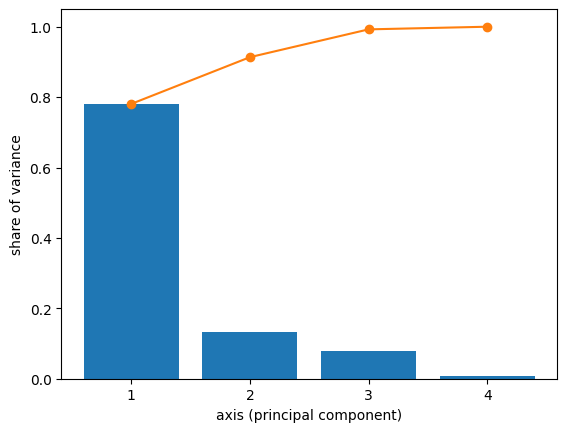

[0.7808 0.9135 0.9925 1.    ]
     fallenr20  totdeg  facnum  stem_rsd
PC1      0.516   0.536   0.470     0.474
PC2     -0.541  -0.400   0.550     0.495
PC3     -0.014  -0.026  -0.687     0.726
PC4     -0.664   0.743  -0.068    -0.051


In [18]:
share = pca4.explained_variance_ratio_
plt.bar(range(1, 5), share)
plt.plot(range(1, 5), share.cumsum(), marker="o", color="C1")
plt.xticks(range(1, 5)); plt.xlabel("axis (principal component)")
plt.ylabel("share of variance"); plt.show()
print(share.cumsum().round(4))
print(pd.DataFrame(pca4.components_, columns=four,
                   index=["PC1", "PC2", "PC3", "PC4"]).round(3))

In [19]:
def first_axis(X):
    pca = PCA()
    pca.fit(X)
    w = pd.Series(pca.components_[0], index=X.columns).abs()
    print(round(float(pca.explained_variance_ratio_[0]), 4),
          w.idxmax(), round(float(w.max()), 3))
first_axis(d[four])                             # no scaler
thousands = d[four].copy()
thousands["fallenr20"] = thousands["fallenr20"] / 1000
first_axis(thousands)                   # same campuses, new units
first_axis(pd.DataFrame(Z4, columns=four))      # standardized
print(d[four].std().round(0).values)            # the four SDs

0.9932 fallenr20 0.965
0.976 totdeg 0.989
0.7808 totdeg 0.536
[14835.  4124.   886.   131.]


In [20]:
from sklearn.pipeline import make_pipeline
for name, X in [("raw", d[four]), ("thousands", thousands),
                ("standardized", pd.DataFrame(Z4, columns=four))]:
    p = PCA()
    p.fit(X)
    print(name, pd.Series(p.components_[0], index=four).round(3).to_dict())
scaled_pca = make_pipeline(StandardScaler(), PCA())
scaled_pca.fit(thousands)                  # any units in, the same axes out
print(scaled_pca[-1].explained_variance_ratio_.round(4))

raw {'fallenr20': 0.965, 'totdeg': 0.26, 'facnum': 0.035, 'stem_rsd': 0.005}
thousands {'fallenr20': 0.003, 'totdeg': 0.989, 'facnum': 0.147, 'stem_rsd': 0.022}
standardized {'fallenr20': 0.516, 'totdeg': 0.536, 'facnum': 0.47, 'stem_rsd': 0.474}
[0.7808 0.1328 0.079  0.0075]
